In [2]:
import sys
import os
base_dir = r"C:\Users\acostamendoza\projects\distance-project"
data_dir = r"D:\data-distance-coding-project\processed-data"
sys.path.append(base_dir)
from src.workflows import analyze_session, batch_analyze_sessions, combine_animal_sessions, batch_combine_and_export, WidefieldAligner
from src.viz.SessionVisualizer import SessionVisualizer
from src.viz.WidefieldVisualizer import WidefieldVisualizer
import numpy as np
import matplotlib.pyplot as plt
from src.decoding.SessionAggregator import SessionAggregator
from src.data.RadialDevice import RadialDevice
from src.viz.CellVisualizer import CellVisualizer
from src.viz.SessionVisualizer import SessionVisualizer
from src.workflows import load_dataframe
from src.decoding.SessionAggregator import SessionAggregator
from src.decoding.NNDecoder import NNDecoder

%load_ext autoreload
%autoreload 2

mouse_name = 'SAM040'
experiment_name = 'tiling_120um'

base_data_dir = r'D:\data-distance-coding-project\processed-data'
multi_session_dir = r'D:\data-distance-coding-project\multi-session-data'

agg = SessionAggregator(mouse_name=mouse_name, experiment_name=experiment_name)
combined_df = load_dataframe(mouse_name=mouse_name, experiment_name=experiment_name)
session_viz = SessionVisualizer(combined_df, mouse_name=mouse_name, experiment_name=experiment_name)


[ok] Loaded aggregated traces from cache
[ok] Loaded DataFrame from D:/data-distance-coding-project/multi-session-data\SAM040_tiling_120um\SAM040_tiling_120um_combined_sessions.pkl (14173 cells)


In [ ]:
reliable_cells = session_viz.filter_by_reliability(combined_df, reliable_type='reliable', threshold=0.85)
session_cells = session_viz.filter_by_session(reliable_cells, session_name='251130_SAM040_tiling_2_120um')
binocular_cells = session_viz.filter_by_modulation(session_cells, modulation_type='binocular')['cell_id'].values

[  60   79   84   97  134  138  171  213  214  239  242  255  278  302
  312  325  332  358  364  377  381  396  417  419  443  457  462  463
  468  473  477  517  534  560  578  580  581  583  599  600  610  626
  632  654  658  670  677  705  708  721  757  785  795  797  810  842
  848  849  852  861  864  880  887  961  971 1005 1006 1007 1017 1028
 1040 1055 1074 1091 1125 1129 1134 1142 1159 1171 1184 1197 1225 1241
 1307 1326 1341 1367 1464 1478 1483 1560 1565 1567 1568 1586 1587 1613
 1699 1720 1732 1754 1774 1780 1789 1800 1832 1878 2044 2112 2138 2169
 2251 2280 2284 2304 2339 2516 2552 2618 2628 2655 2759 3352 3388 3729
 3894 3896]


In [40]:
device = RadialDevice(mouse_name=mouse_name, record_date=251130, experiment_name='tiling_2_120um')
cell_viz = CellVisualizer(device)

[ok] Loading session: 251130_SAM040_tiling_2_120um
Directory results already exists
Successfully loaded activity data
Stimulus file found
Repeat stimulus on length distribution:
    96 repeats have length 61
    24 repeats have length 62
Set stimulus on length: 61


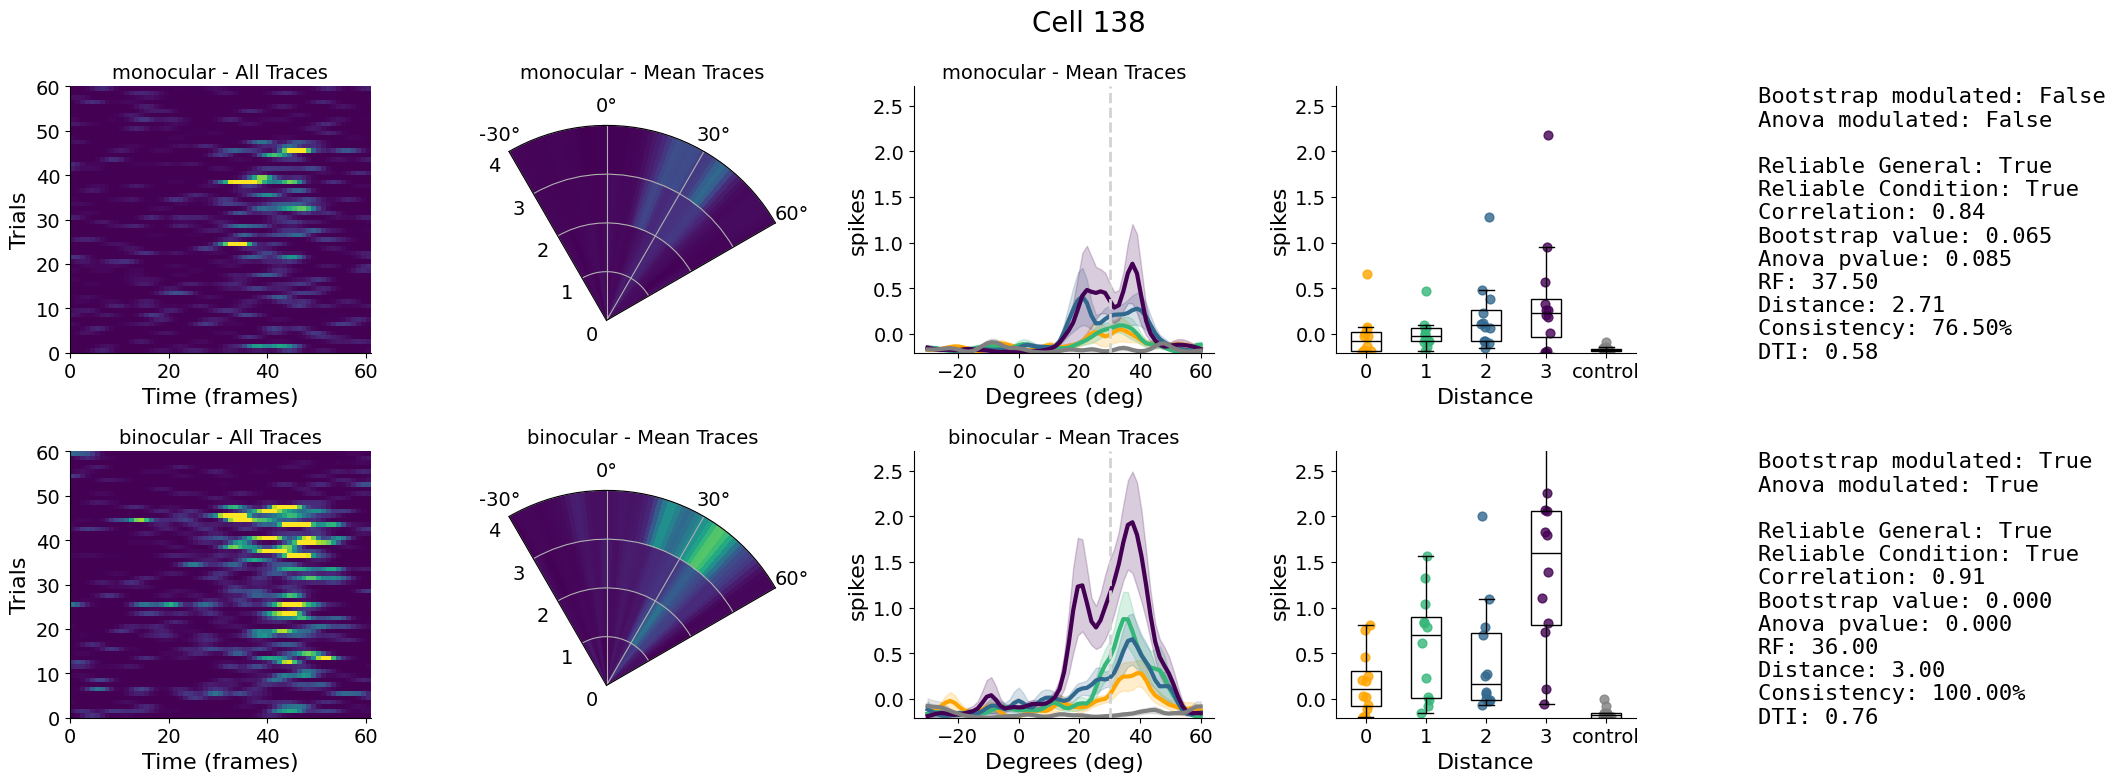

In [55]:
fig = cell_viz.plot_all_traces_colormap_distances(cell=138)

In [62]:
X, y_dist = agg.get_cell_traces(cell_id=138, session_name='251130_SAM040_tiling_2_120um', monocular=0, distance=0)

[ok] Loaded aggregated traces from cache
Fold 10/10
Total test samples: 48
  MAE:          2.74
  RMSE:         3.97
  Correlation:  0.989
  R²:           0.977


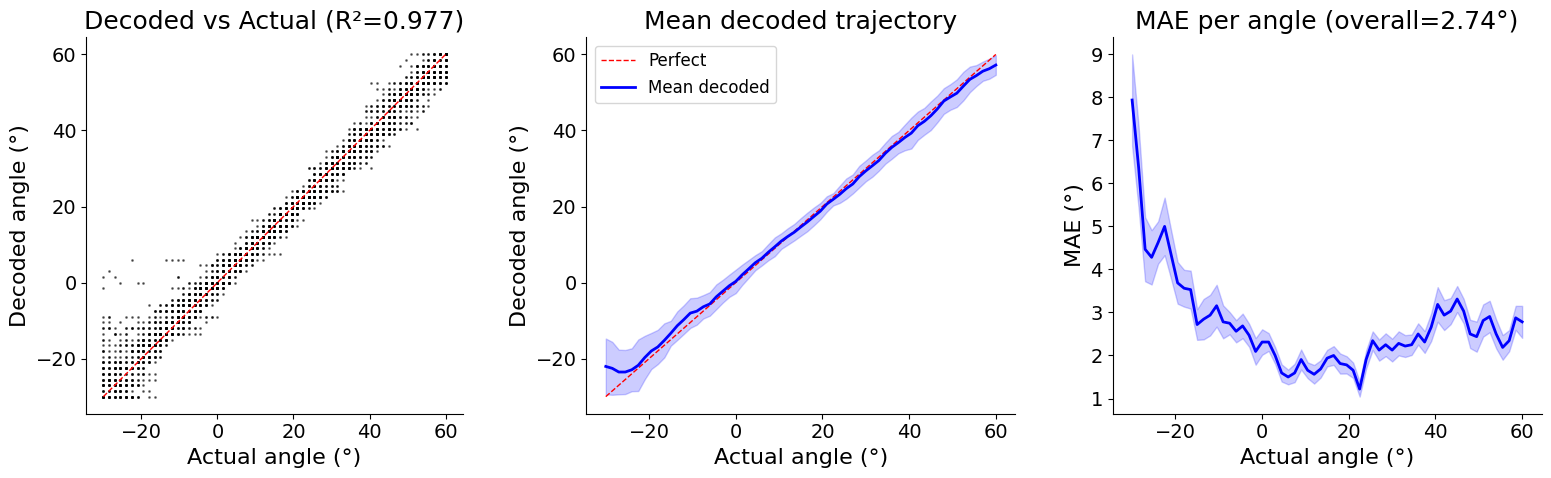

In [11]:
from src.decoding.SessionAggregator import SessionAggregator
from src.decoding.Decoders import MLE

# Get aggregated data
agg = SessionAggregator('SAM043', 'tiling_120um')
X, y = agg.get_decoder_data(monocular=1)

# Define angle range
angle_range = np.linspace(-30, 60, X.shape[1])
# Create decoder
decoder = MLE(angle_range)
# K-fold CV
results = decoder.cross_validate(X, n_folds=10)
# Plot
comparison = decoder.plot_results(results)

[ok] Loaded aggregated traces from cache
Fold 10/10
Total test samples: 48
  MAE:          3.76
  RMSE:         5.60
  Correlation:  0.978
  R²:           0.955
Fold 10/10
Total test samples: 48
  MAE:          3.02
  RMSE:         4.48
  Correlation:  0.986
  R²:           0.971


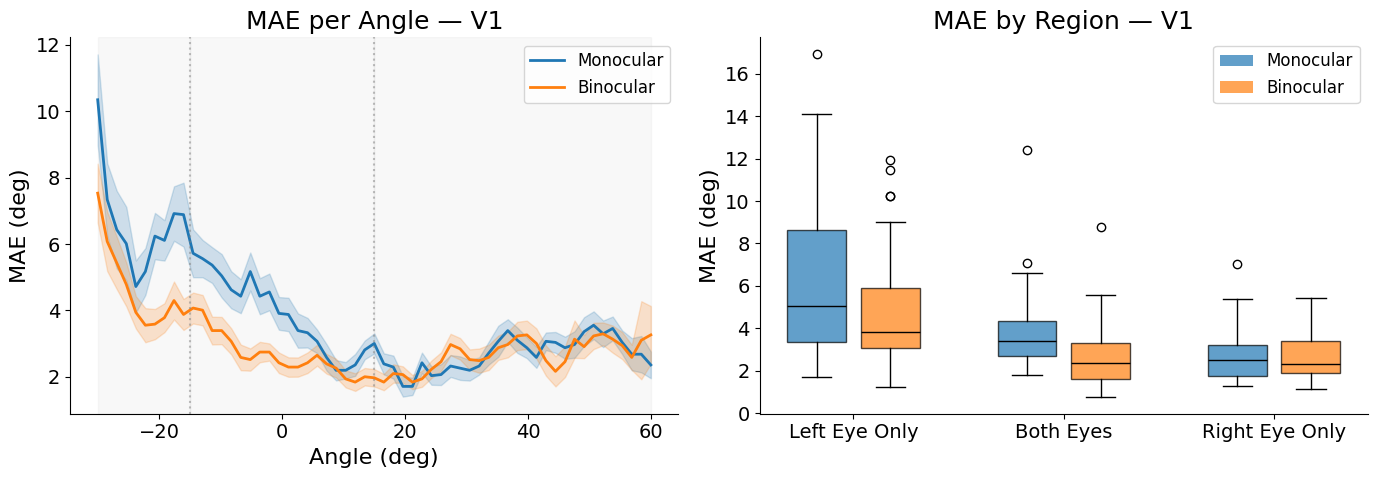

In [44]:
from src.decoding.Decoders import plot_mae_by_angle_range
from src.decoding.SessionAggregator import SessionAggregator

agg = SessionAggregator('SAM041', 'tiling_120um')
plot_mae_by_angle_range(agg, area='V1', n_folds=10)

In [ ]:
agg = SessionAggregator('SAM040', 'tiling_120um')

monocular_results = dict()
binocular_results = dict()

for area in agg.available_areas:

    print(f'Decoding {area}')

    X, y_distance = agg.get_decoder_data(monocular=0, area=area)
    decoder = NNDecoder(chunk_size=1)
    results = decoder.cross_validate_mean(X, y_distance, n_repeats=50)
    binocular_results[area] = results

    X, y_distance = agg.get_decoder_data(monocular=1, area=area)
    decoder = NNDecoder(chunk_size=1)
    results = decoder.cross_validate_mean(X, y_distance, n_repeats=50)
    monocular_results[area] = results

[ok] Loaded aggregated traces from cache
Decoding V1
Repeat 50/50
Total predictions: 12000
Repeats: 50, Distances: 4
NN DECODER PERFORMANCE
  DISTANCE:
    MAE:          0.833
    RMSE:         1.123
    Bias:         0.021
    Correlation:  0.442

  ANGLE:
    MAE:          0.10
    RMSE:         0.12
    R²:           0.837
    Correlation:  0.969

  Reference (random distance MAE ~ 1.25)
Repeat 50/50
Total predictions: 12000
Repeats: 50, Distances: 4
NN DECODER PERFORMANCE
  DISTANCE:
    MAE:          1.135
    RMSE:         1.397
    Bias:         -0.052
    Correlation:  0.113

  ANGLE:
    MAE:          0.11
    RMSE:         0.13
    R²:           0.817
    Correlation:  0.966

  Reference (random distance MAE ~ 1.25)
Decoding None
Repeat 50/50
Total predictions: 12000
Repeats: 50, Distances: 4
NN DECODER PERFORMANCE
  DISTANCE:
    MAE:          1.109
    RMSE:         1.355
    Bias:         0.001
    Correlation:  0.100

  ANGLE:
    MAE:          0.08
    RMSE:         0.10

In [55]:
import pickle
import os

session_dir = os.path.join(agg.multi_session_dir, f'{agg.mouse_name}_{agg.experiment_name}')
filename_binocular = os.path.join(session_dir, f'{agg.mouse_name}_{agg.experiment_name}_binocular_results.pkl')
filename_monocular = os.path.join(session_dir, f'{agg.mouse_name}_{agg.experiment_name}_monocular_results.pkl')

with open(filename_binocular, 'wb') as f:
    pickle.dump(binocular_results, f)

with open(filename_monocular, 'wb') as f:
    pickle.dump(monocular_results, f)


In [56]:
import pickle
import os

with open(filename_binocular, 'rb') as f:
    binocular_results = pickle.load(f)

with open(filename_monocular, 'rb') as f:
    monocular_results = pickle.load(f)

In [57]:
print(binocular_results.keys())

dict_keys(['V1', 'None', 'LM', 'RL', 'PM', 'AM', 'AL'])


In [53]:
agg.multi_session_dir

'D:\\data-distance-coding-project\\multi-session-data'

In [48]:
print(binocular_results.keys())

dict_keys(['all_decoded_dist', 'all_actual_dist', 'all_decoded_angle', 'all_actual_angle', 'all_angle_indices', 'dist_metrics', 'angle_metrics'])


In [45]:
print(binocular_results)

NameError: name 'binocular_results' is not defined

[ok] Loaded aggregated traces from cache
Repeat 50/50
Total predictions: 12000
Repeats: 50, Distances: 4
NN DECODER PERFORMANCE
  DISTANCE:
    MAE:          0.995
    RMSE:         1.274
    Bias:         -0.062
    Correlation:  0.257

  ANGLE:
    MAE:          0.06
    RMSE:         0.08
    R²:           0.934
    Correlation:  0.976

  Reference (random distance MAE ~ 1.25)


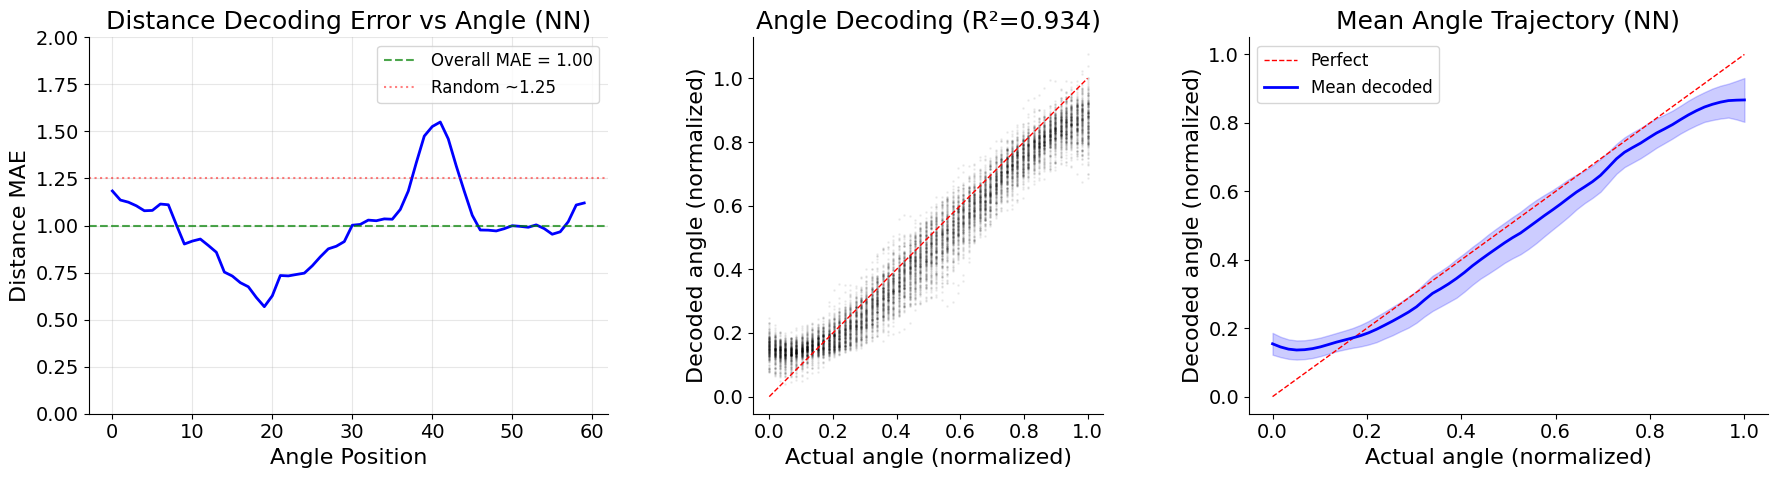

Repeat 50/50
Total predictions: 12000
Repeats: 50, Distances: 4
NN DECODER PERFORMANCE
  DISTANCE:
    MAE:          1.230
    RMSE:         1.511
    Bias:         -0.049
    Correlation:  -0.103

  ANGLE:
    MAE:          0.08
    RMSE:         0.10
    R²:           0.879
    Correlation:  0.959

  Reference (random distance MAE ~ 1.25)


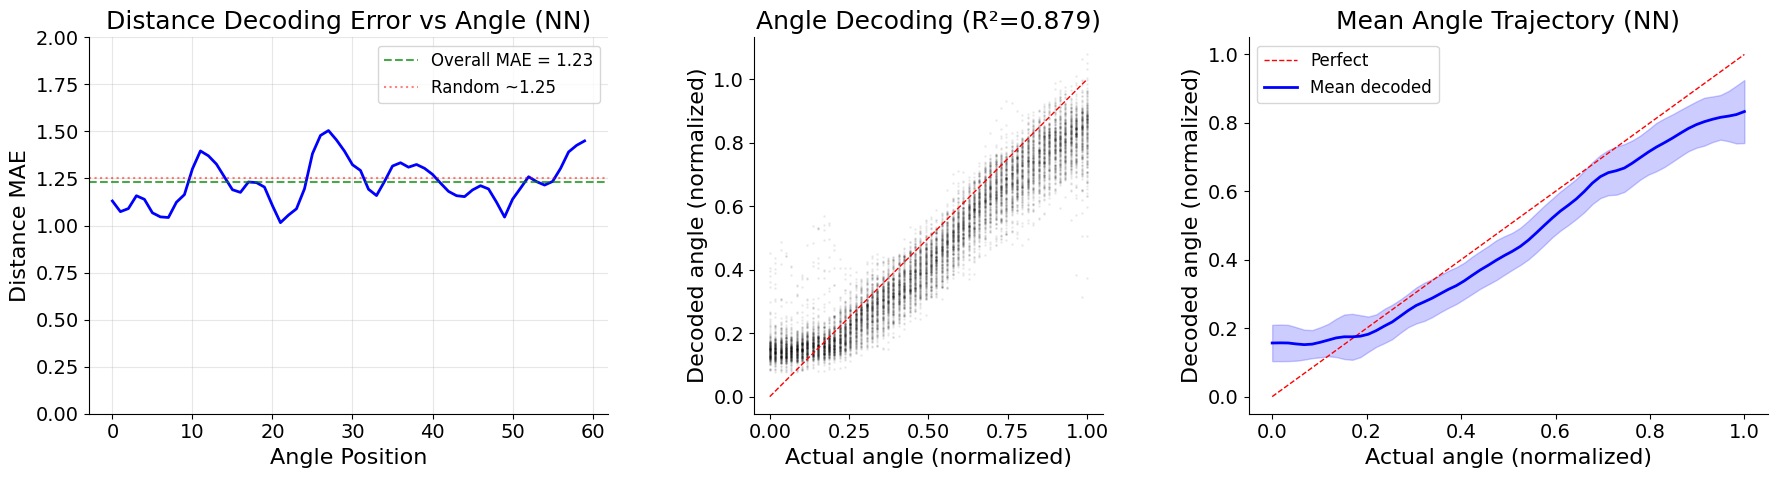

: 

In [ ]:
agg = SessionAggregator('SAM040', 'tiling_120um')

X, y_distance = agg.get_decoder_data(monocular=0, area='LM')
decoder = NNDecoder(chunk_size=1)
binocular_LM_results = decoder.cross_validate_mean(X, y_distance, n_repeats=50)
figure = decoder.plot_results(binocular_LM_results)

X, y_distance = agg.get_decoder_data(monocular=1, area='LM')
decoder = NNDecoder(chunk_size=1)
monocular_LM_results = decoder.cross_validate_mean(X, y_distance, n_repeats=50)
figure = decoder.plot_results(monocular_LM_results)

[ok] Loaded aggregated traces from cache
Repeat 50/50
Total predictions: 12000
Repeats: 50, Distances: 4
NN DECODER PERFORMANCE
  DISTANCE:
    MAE:          1.255
    RMSE:         1.481
    Bias:         -0.040
    Correlation:  -0.061

  ANGLE:
    MAE:          0.06
    RMSE:         0.08
    R²:           0.929
    Correlation:  0.975

  Reference (random distance MAE ~ 1.25)


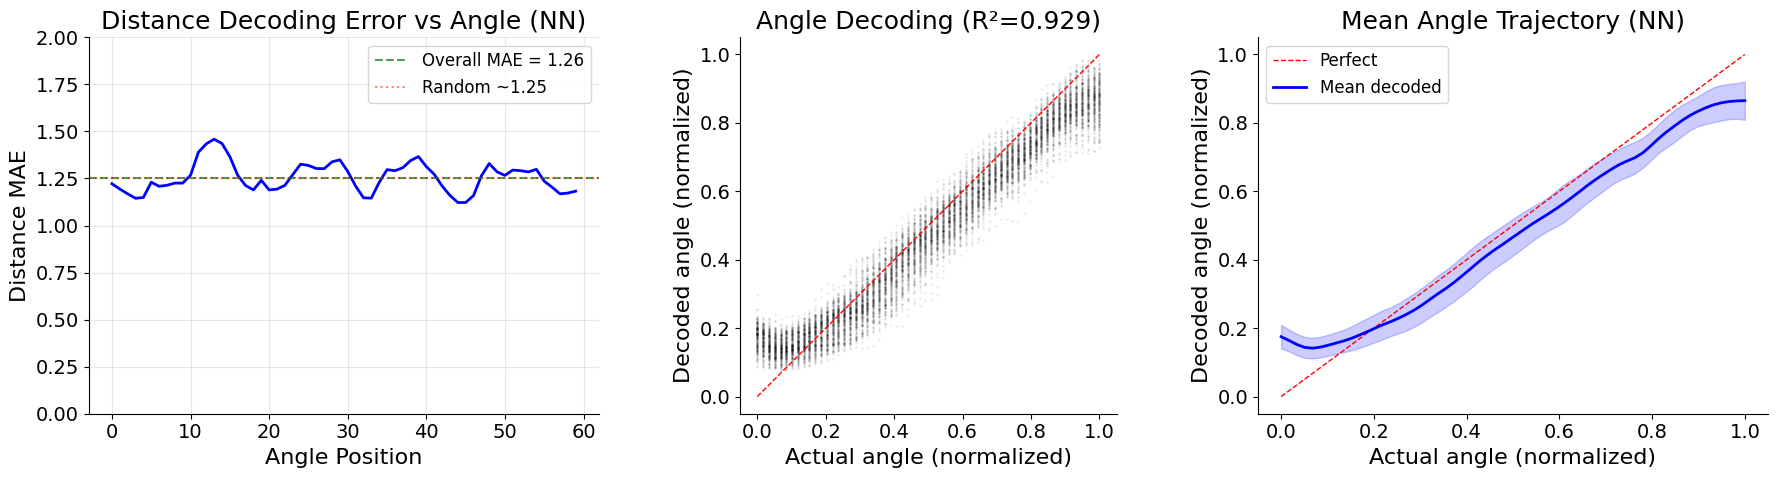

Repeat 50/50
Total predictions: 12000
Repeats: 50, Distances: 4
NN DECODER PERFORMANCE
  DISTANCE:
    MAE:          1.373
    RMSE:         1.590
    Bias:         -0.074
    Correlation:  -0.218

  ANGLE:
    MAE:          0.10
    RMSE:         0.13
    R²:           0.813
    Correlation:  0.941

  Reference (random distance MAE ~ 1.25)


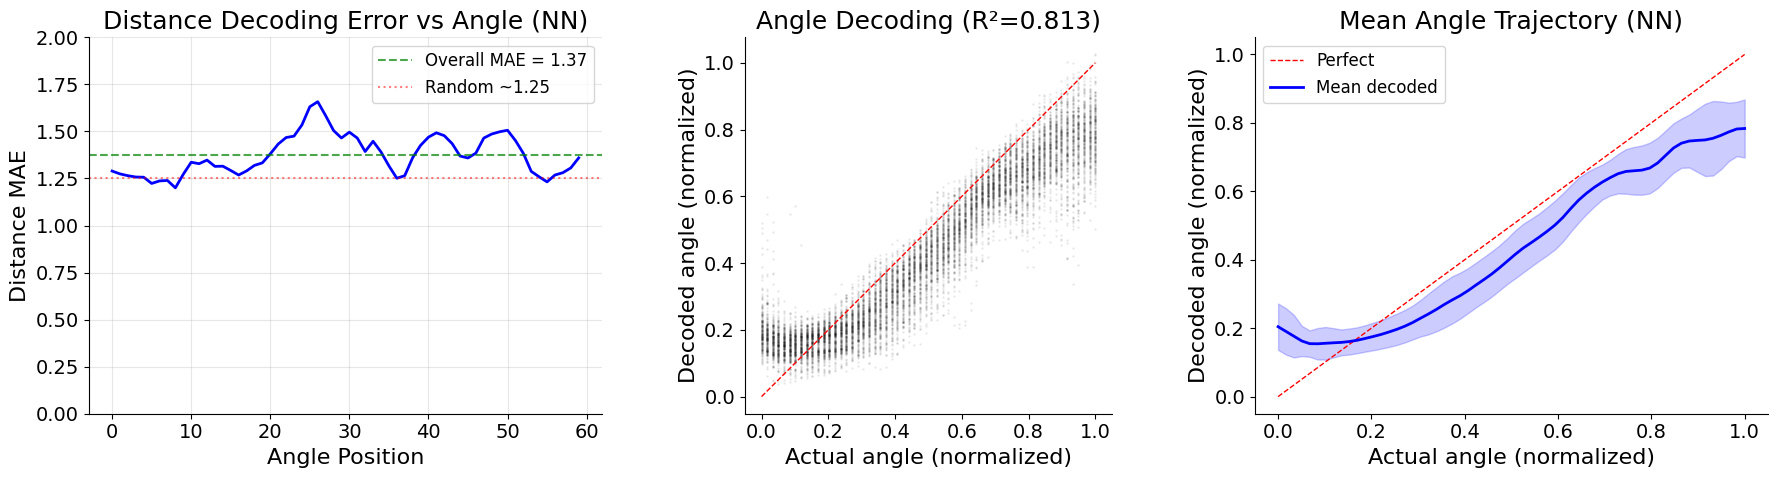

In [4]:
agg = SessionAggregator('SAM040', 'tiling_120um')

X, y_distance = agg.get_decoder_data(monocular=0, area='RL')
decoder = NNDecoder(chunk_size=1)
binocular_RL_results = decoder.cross_validate_mean(X, y_distance, n_repeats=50)
figure = decoder.plot_results(binocular_RL_results)

X, y_distance = agg.get_decoder_data(monocular=1, area='RL')
decoder = NNDecoder(chunk_size=1)
monocular_RL_results = decoder.cross_validate_mean(X, y_distance, n_repeats=50)
figure = decoder.plot_results(monocular_RL_results)

[ok] Loaded aggregated traces from cache
Repeat 50/50
Total predictions: 12000
Repeats: 50, Distances: 4
NN DECODER PERFORMANCE
  DISTANCE:
    MAE:          0.867
    RMSE:         1.152
    Bias:         0.051
    Correlation:  0.413

  ANGLE:
    MAE:          0.10
    RMSE:         0.12
    R²:           0.831
    Correlation:  0.969

  Reference (random distance MAE ~ 1.25)


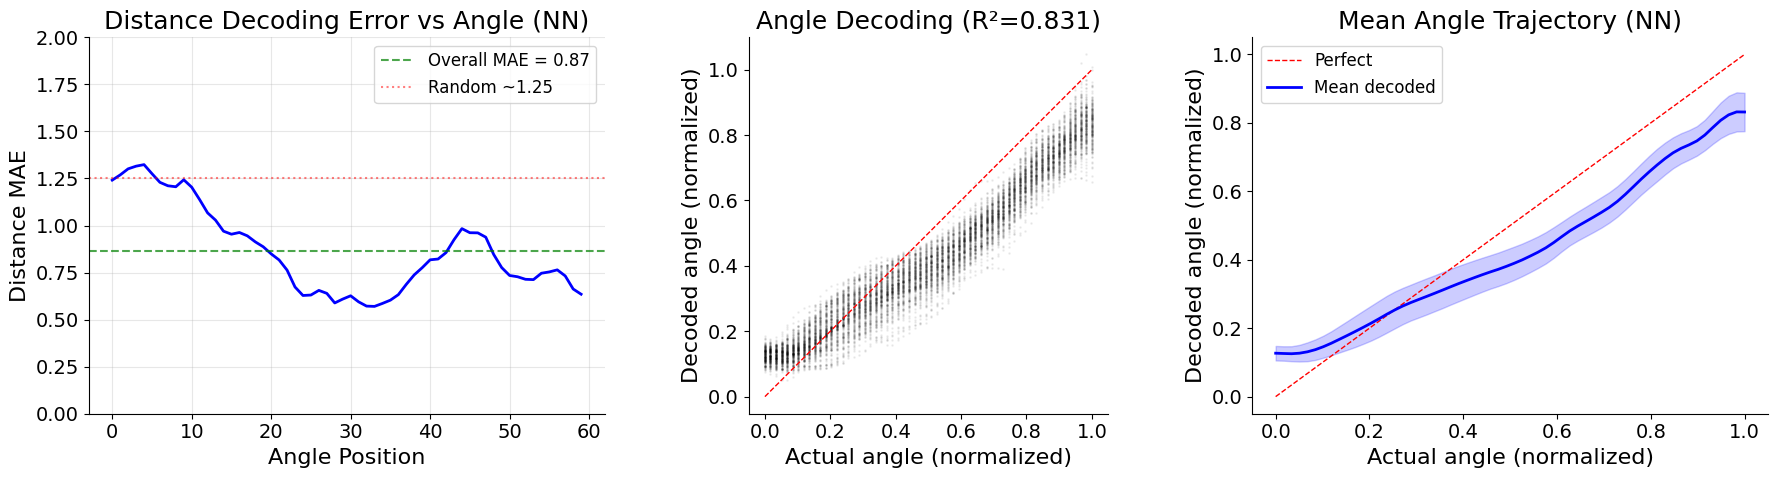

Repeat 50/50
Total predictions: 12000
Repeats: 50, Distances: 4
NN DECODER PERFORMANCE
  DISTANCE:
    MAE:          1.105
    RMSE:         1.368
    Bias:         -0.059
    Correlation:  0.151

  ANGLE:
    MAE:          0.11
    RMSE:         0.13
    R²:           0.808
    Correlation:  0.966

  Reference (random distance MAE ~ 1.25)


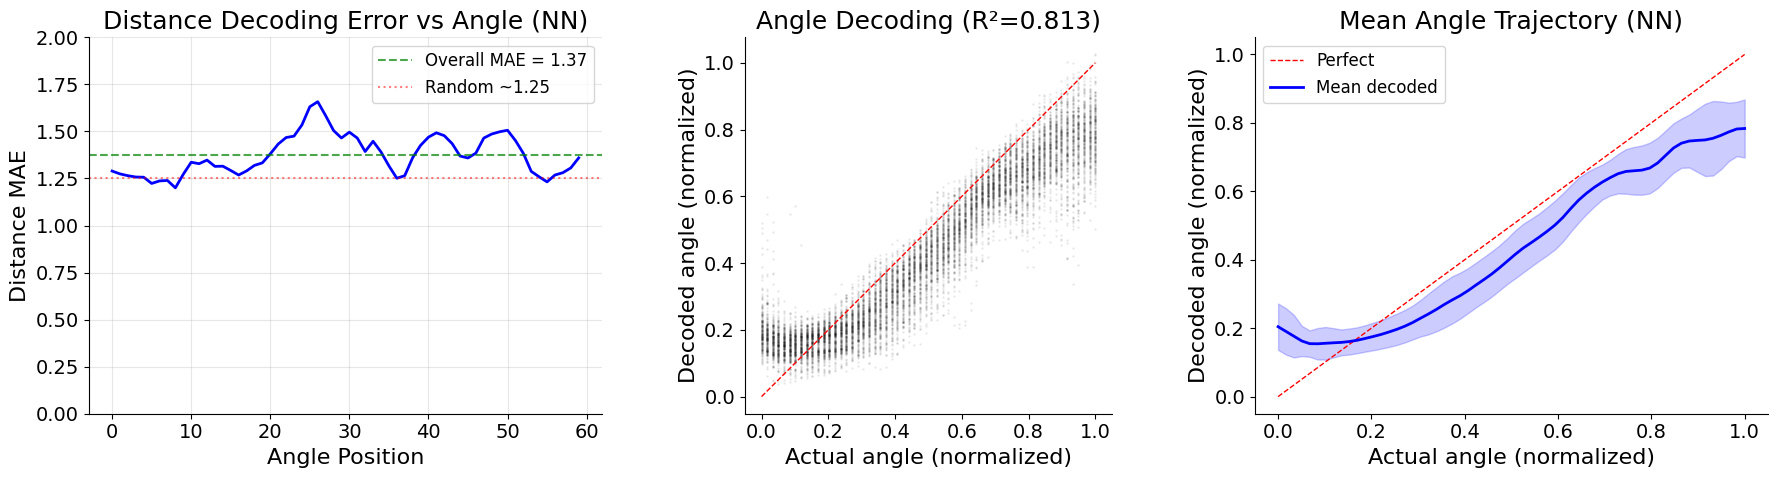

In [5]:
agg = SessionAggregator('SAM040', 'tiling_120um')

X, y_distance = agg.get_decoder_data(monocular=0, area='V1')
decoder = NNDecoder(chunk_size=1)
binocular_V1_results = decoder.cross_validate_mean(X, y_distance, n_repeats=50)
figure = decoder.plot_results(binocular_V1_results)

X, y_distance = agg.get_decoder_data(monocular=1, area='V1')
decoder = NNDecoder(chunk_size=1)
monocular_V1_results = decoder.cross_validate_mean(X, y_distance, n_repeats=50)
figure = decoder.plot_results(monocular_RL_results)

Repeat 50/50
Total predictions: 12000
Repeats: 50, Distances: 4
NN DECODER PERFORMANCE
  DISTANCE:
    MAE:          0.753
    RMSE:         1.062
    Bias:         0.011
    Correlation:  0.508

  ANGLE:
    MAE:          0.09
    RMSE:         0.10
    R²:           0.873
    Correlation:  0.970

  Reference (random distance MAE ~ 1.25)


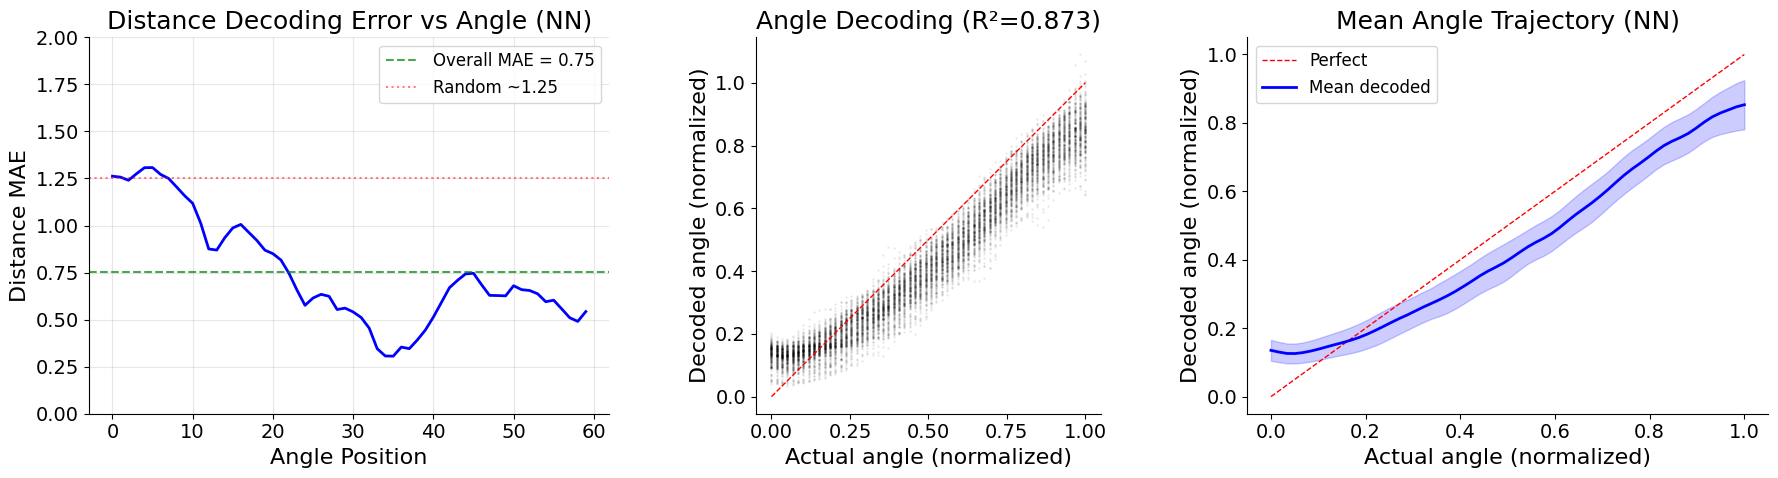

Repeat 50/50
Total predictions: 12000
Repeats: 50, Distances: 4
NN DECODER PERFORMANCE
  DISTANCE:
    MAE:          1.119
    RMSE:         1.393
    Bias:         -0.081
    Correlation:  0.083

  ANGLE:
    MAE:          0.08
    RMSE:         0.10
    R²:           0.874
    Correlation:  0.963

  Reference (random distance MAE ~ 1.25)


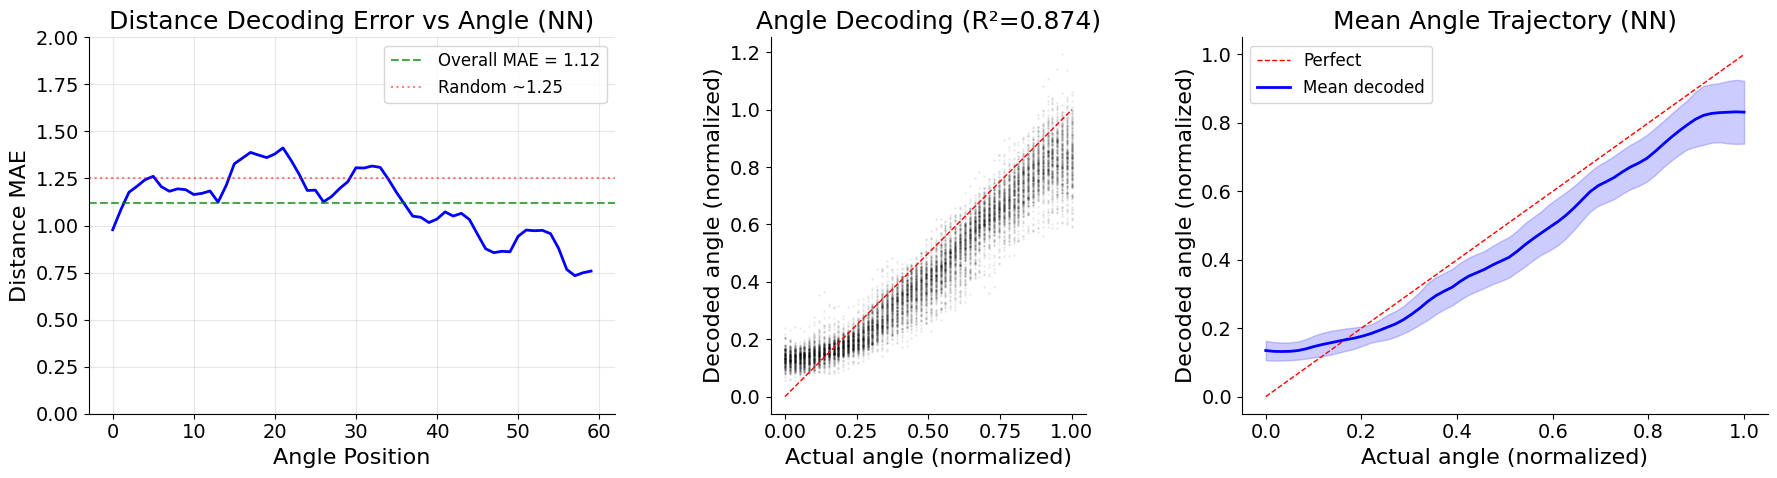

In [10]:
X, y_distance = agg.get_decoder_data(monocular=0, modulated_only=True)
decoder = NNDecoder(chunk_size=1)
binocular_results = decoder.cross_validate_mean(X, y_distance, n_repeats=50)
figure = decoder.plot_results(binocular_results)

X, y_distance = agg.get_decoder_data(monocular=1, modulated_only=True)
decoder = NNDecoder(chunk_size=1)
monocular_results = decoder.cross_validate_mean(X, y_distance, n_repeats=50)
figure = decoder.plot_results(monocular_results)

              NN DECODER COMPARISON               
Metric              binocular      monocular      
--------------------------------------------------
MAE                 0.753          1.119          
RMSE                1.062          1.393          
CORR                0.508          0.083          
ACCURACY            44.3%          26.6%          


(<Figure size 1000x500 with 1 Axes>,
 {'labels': ['binocular', 'monocular'],
  'metrics': [{'mae': np.float64(0.753314106816348),
    'rmse': np.float64(1.0619849542434514),
    'corr': np.float64(0.508159304822904),
    'accuracy': np.float64(0.44325)},
   {'mae': np.float64(1.1190146974607427),
    'rmse': np.float64(1.3926014546066223),
    'corr': np.float64(0.08316426777282394),
    'accuracy': np.float64(0.2659166666666667)}]})

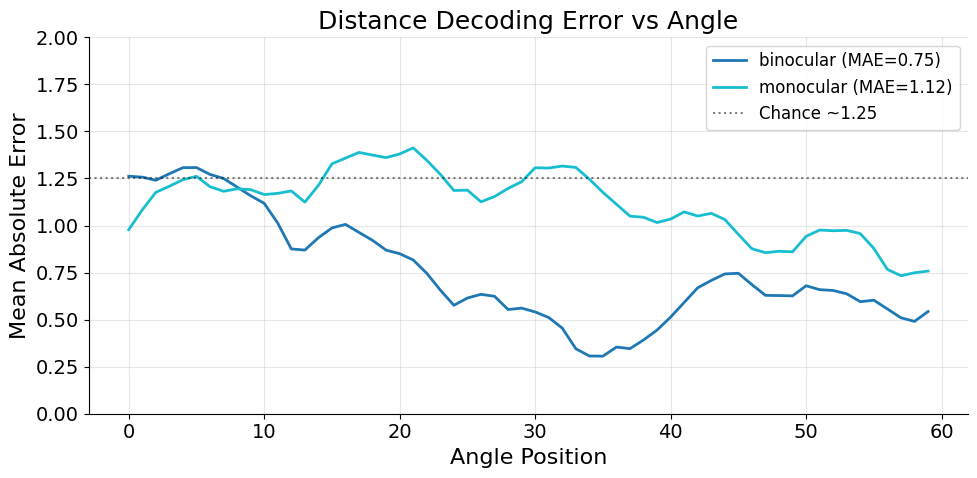

In [11]:
decoder.plot_compare_results([binocular_results, monocular_results], ['binocular', 'monocular'])

[ok] Loaded aggregated traces from cache
Repeat 50/50
Total predictions: 12000
Repeats: 50, Distances: 4
NN DECODER PERFORMANCE
  DISTANCE:
    MAE:          1.144
    RMSE:         1.412
    Bias:         -0.026
    Correlation:  0.081

  ANGLE:
    MAE:          0.11
    RMSE:         0.13
    R²:           0.794
    Correlation:  0.962

  Reference (random distance MAE ~ 1.25)


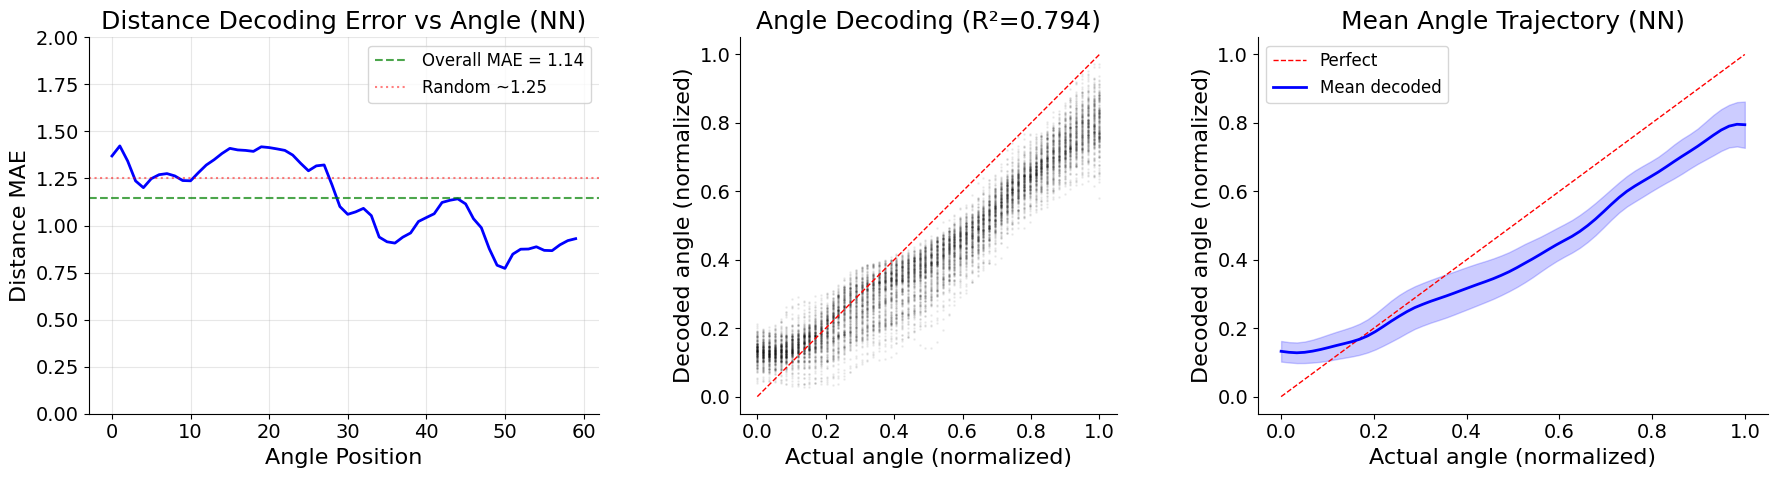

In [151]:
agg = SessionAggregator('SAM040', 'tiling_120um')
X, y_distance = agg.get_decoder_data(monocular=1, area= 'V1')

decoder = NNDecoder(chunk_size=1)
results = decoder.cross_validate_mean(X, y_distance, n_repeats=50)
figure = decoder.plot_results(results)

In [176]:
fig, metrics = LinearRFDistanceDecoder.plot_accuracy_by_angle(results)

KeyError: 'decoded_distances'

Repeat 100/100
Total predictions: 400 (100 repeats × 4 distances)
LINEAR RF DISTANCE DECODER PERFORMANCE
  Mean Absolute Error:  1.010
  RMSE:                 1.135
  Bias:                 -0.008
  Std:                  1.135
  Correlation:          0.161

  Reference (random guess MAE ~ 1.25)


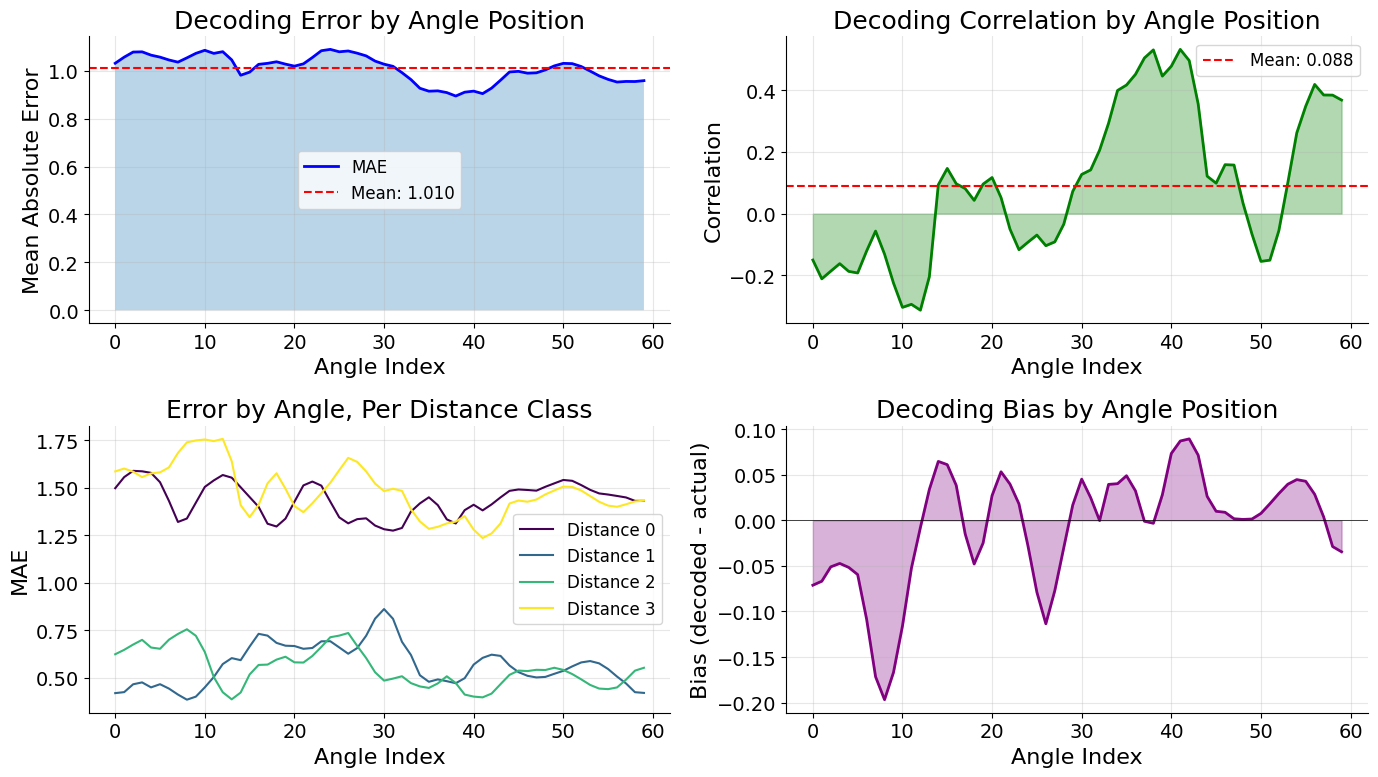

In [166]:
# Create decoder
decoder = LinearRFDistanceDecoder(window_size=10, use_rf_interaction=True)

# Run cross-validation with condition pooling
results = decoder.cross_validate_pooled(
    agg,
    area = 'LM',
    monocular=1,
    n_repeats=100
)

# Plot accuracy by angle
fig, metrics = decoder.plot_accuracy_by_angle(results)

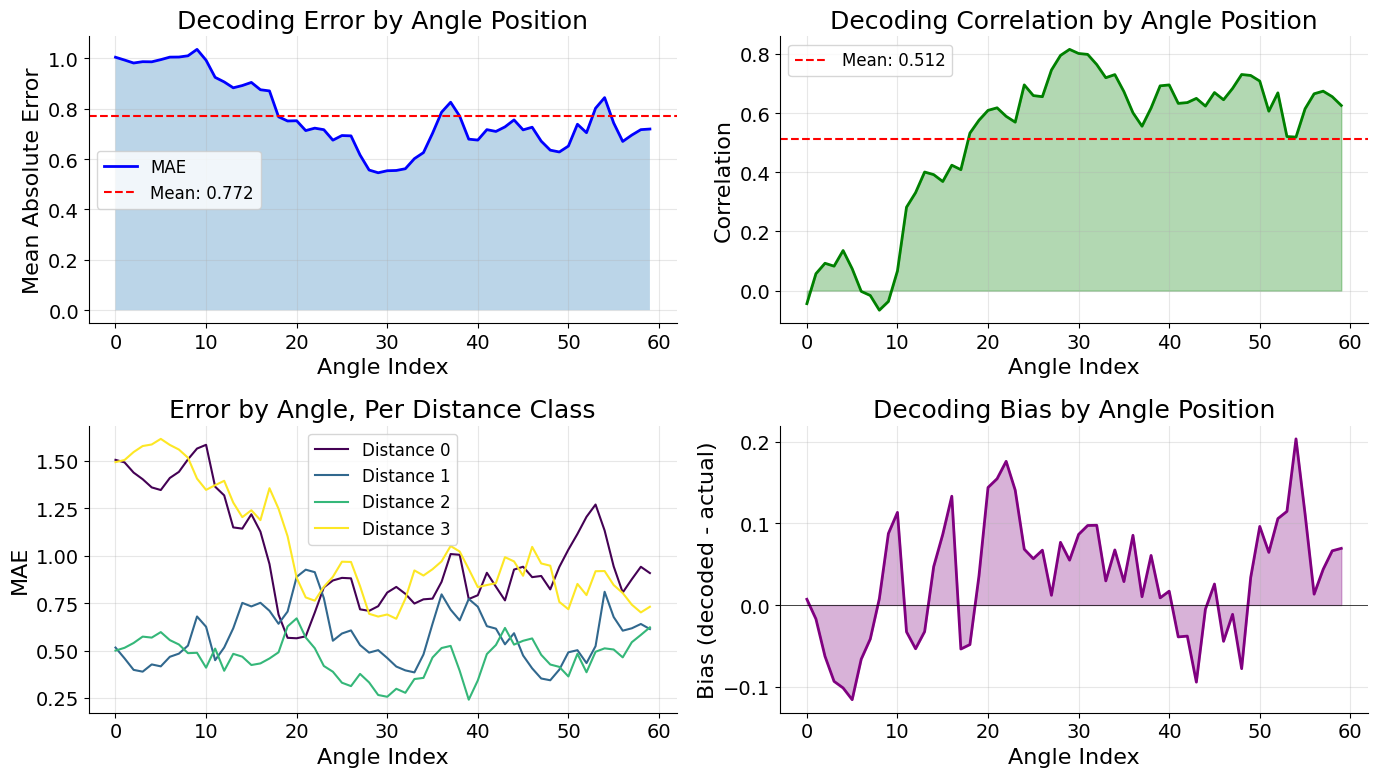

[1.0038657  0.99275099 0.98097834 0.98622396 0.98570088 0.99433044
 1.00429647 1.00465737 1.00955927 1.03508555 0.99200919 0.92405464
 0.90591755 0.88256396 0.8915414  0.9039252  0.8748961  0.87019514
 0.76752783 0.75086453 0.75182201 0.71277764 0.72240647 0.71634663
 0.67480384 0.6931382  0.69183625 0.61581062 0.55619757 0.54537187
 0.55340399 0.55448484 0.5613342  0.60139864 0.62536813 0.70182383
 0.7857614  0.82529602 0.77005477 0.67873999 0.6751077  0.71653238
 0.70939286 0.72746545 0.75514041 0.71563292 0.72614034 0.67083418
 0.63506196 0.62784573 0.65126108 0.73792885 0.70438592 0.80143446
 0.84361759 0.74303984 0.66970189 0.69489728 0.71649897 0.71894035]
[-0.04407318  0.05725235  0.09250906  0.08275151  0.13563163  0.07423377
 -0.00247807 -0.01643595 -0.06606464 -0.03654516  0.06668301  0.28206039
  0.33129934  0.40093426  0.39214327  0.36890992  0.42403099  0.40890199
  0.53250381  0.5760063   0.60937574  0.6179742   0.5891931   0.56949348
  0.6954932   0.65937611  0.65558337 

In [162]:

# Plot accuracy by angle (static method, works on results dict)
fig, metrics_by_angle = LinearRFDistanceDecoder.plot_accuracy_by_angle(
    results# Optional: use actual angles in degrees
)
plt.show()

# Access the raw metrics
print(metrics_by_angle['mae'])          # MAE at each angle position
print(metrics_by_angle['correlation'])  # Correlation at each angle
print(metrics_by_angle['mae_by_distance'])  # MAE broken down by distance class
